# Week 5 Optimum Progress and Calibration

Compare each evaluated output with its pre-evaluation prediction for weeks 1-5. Track actual and expected best-so-far, then inspect standardized residuals across all eight functions. All predictions are the values saved before evaluation; this notebook is read-only. The Week 5 outcomes are included in the observation histories.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import FUNCTION_SPECS
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.visualisation import plot_calibration, plot_optimum_progress

CURRENT_WEEK = 5
WEEKS = tuple(range(1, CURRENT_WEEK + 1))
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
print(f'Data root: {data_root}')
print(f'Evaluated weeks: {WEEKS}; functions: {FUNCTION_IDS}')

Data root: /home/pabloncho/repositories/bayesian-bbo/data
Evaluated weeks: (1, 2, 3, 4, 5); functions: (1, 2, 3, 4, 5, 6, 7, 8)


## 1. Week 5 outcomes

Residuals are $z = (y - \mu)/\sigma$. Positive values mean the realized output exceeded the saved predictive mean. Compare the measured output with the previous incumbent; the expected-best column is a model expectation, not an observed result.

In [2]:
week5 = history.records.loc[history.records.week == CURRENT_WEEK].copy()
week5['improved_incumbent'] = week5.observed_output > week5.previous_best
week5_table = week5.set_index('function_id')[
    ['previous_best', 'observed_output', 'expected_mean', 'expected_std', 'residual',
     'expected_best', 'observed_best', 'improved_incumbent']
].rename_axis('function_id')
display(week5_table.round(6))
print(f"Week-5 incumbent improvements: {int(week5.improved_incumbent.sum())}/{len(week5)}")

,previous_best,observed_output,expected_mean,expected_std,residual,expected_best,observed_best,improved_incumbent
function_id,,,,,,,,
1,0.000001,0.000006,0.000019,0.000417,-0.030763,0.000176,0.000006,True
2,0.611205,0.610531,0.605378,0.026900,0.191549,0.619274,0.611205,False
3,-0.005895,-0.096282,-0.060350,0.080565,-0.445998,0.006093,-0.005895,False
4,0.687027,0.582951,-0.194162,0.773523,1.004641,0.736121,0.687027,False
5,3949.359248,7156.856542,5312.777889,654.553522,2.817308,5317.215045,7156.856542,True
6,-0.466997,-0.723566,-0.433969,0.105457,-2.746111,-0.406365,-0.466997,False
7,2.367723,1.687241,2.483301,0.095127,-8.368345,2.488476,2.367723,False
8,9.892961,9.854369,9.960552,0.083841,-1.266478,9.970521,9.892961,False


Week-5 incumbent improvements: 2/8


## 2. Best-so-far progress

Actual outputs can fall from one week to the next; observed best-so-far cannot. The expected-best series uses the saved pre-evaluation incumbent plus expected improvement at $\xi=0$. Shaded bands show saved mean $\pm 1.96\sigma$ at each evaluated point and do not imply predictions between weeks.

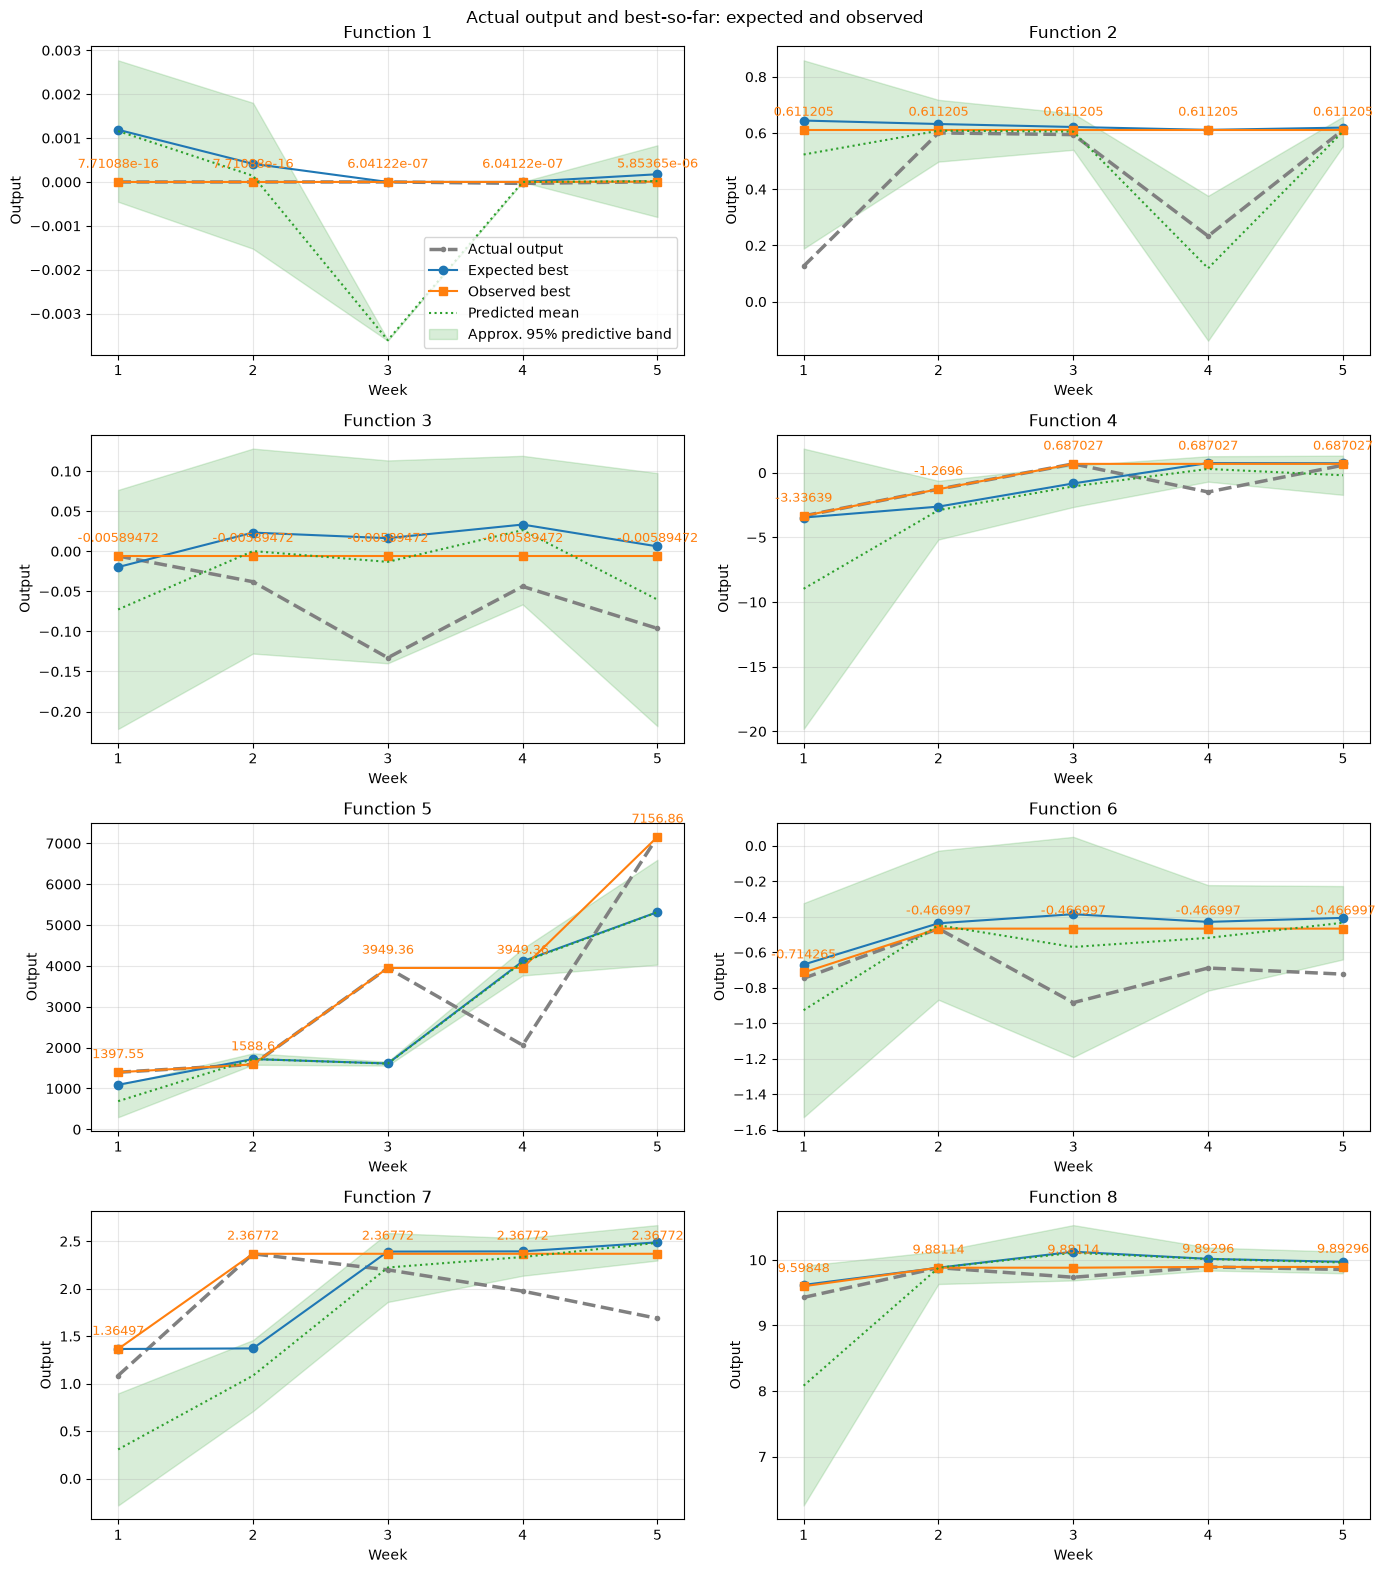

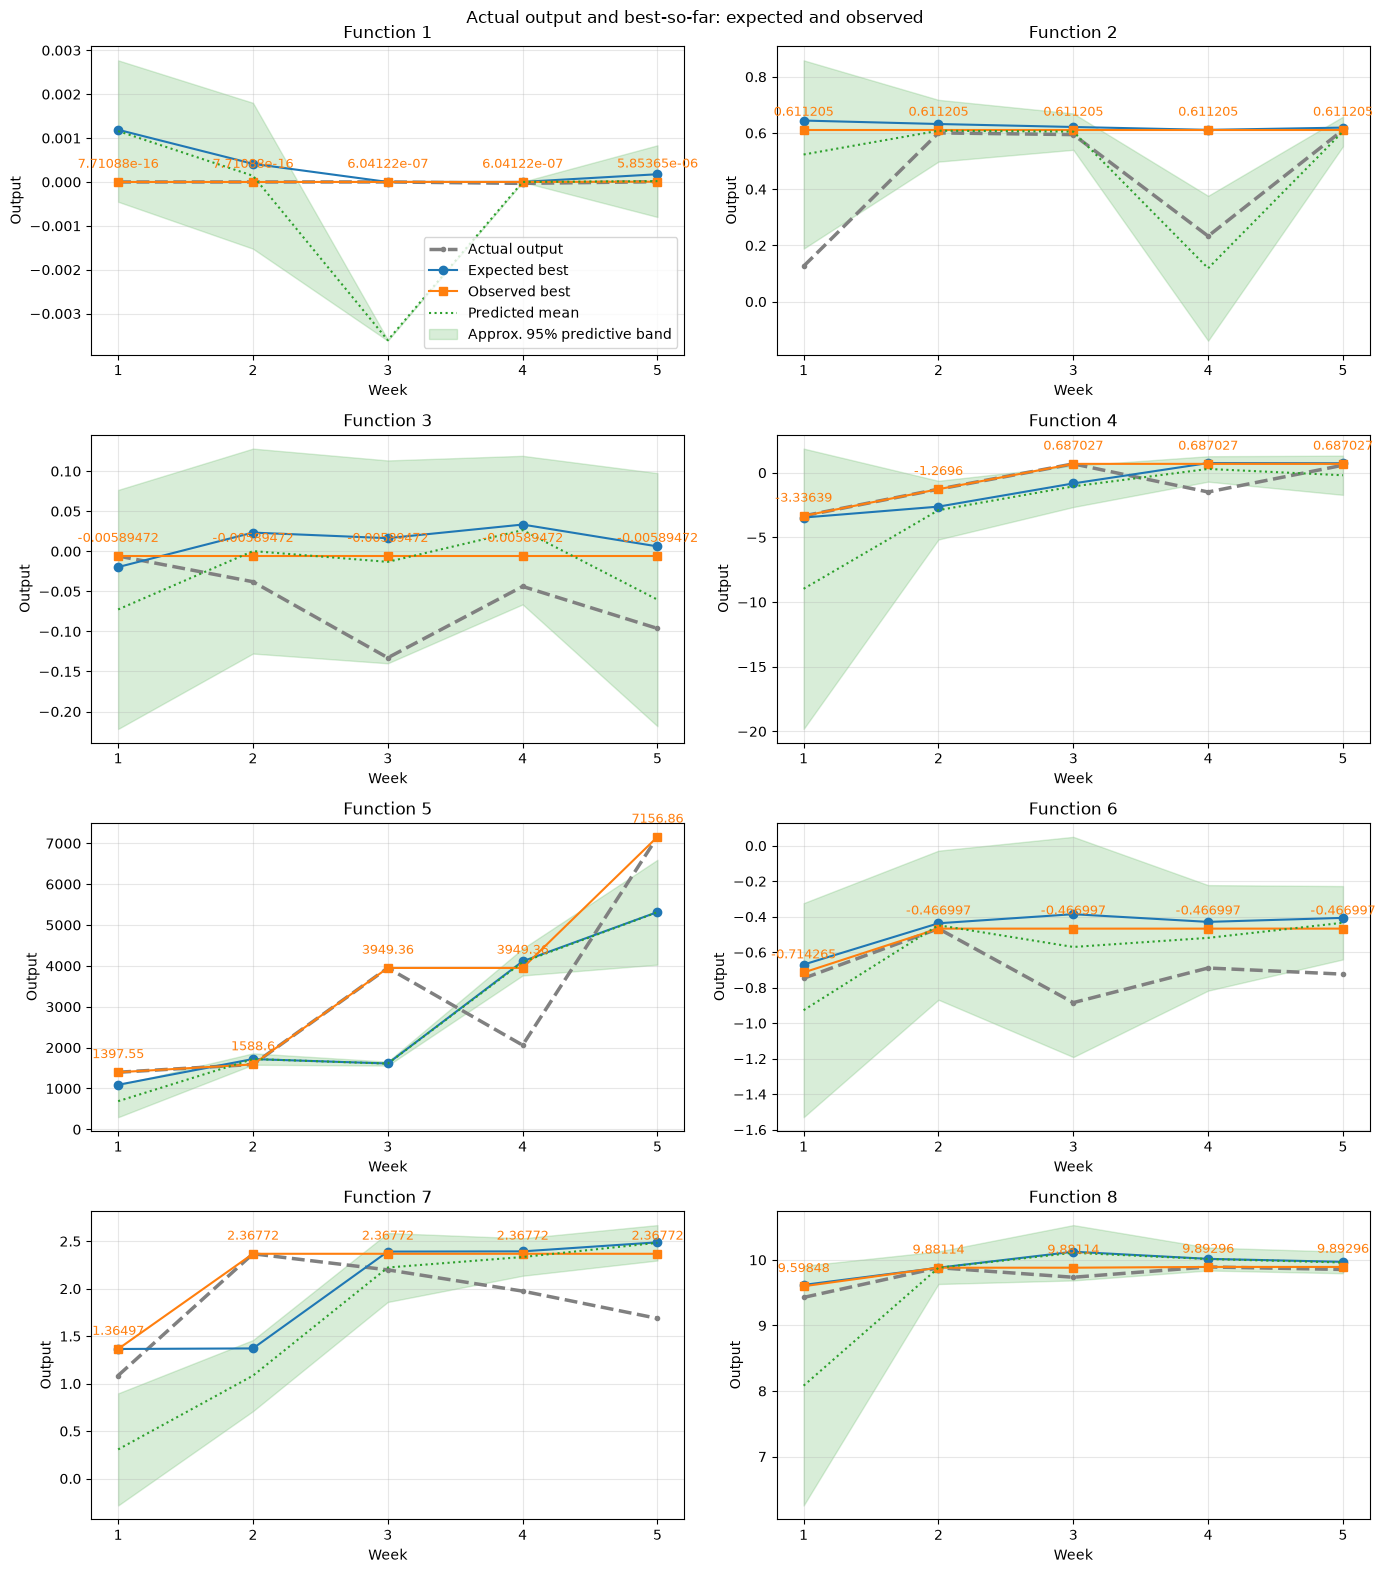

In [3]:
def history_matrix(column):
    return history.records.pivot(index='function_id', columns='week', values=column).reindex(
        index=FUNCTION_IDS, columns=WEEKS,
    ).to_numpy()

actual_outputs = history_matrix('observed_output')
expected_outputs = history_matrix('expected_mean')
stds = history_matrix('expected_std')
expected_best = history_matrix('expected_best')
observed_best = history_matrix('observed_best')
if any(not np.all(np.isfinite(values)) for values in (actual_outputs, expected_outputs, stds, expected_best, observed_best)):
    raise ValueError('Week 1-5 history values must be finite.')
residuals = history.records.groupby('function_id').residual.apply(list).to_dict()

progress_figure, progress_axes = plot_optimum_progress(
    WEEKS, FUNCTION_IDS, actual_outputs, expected_best, observed_best,
    expected_outputs=expected_outputs, stds=stds,
)
display(progress_figure)

## 3. Predictive calibration

The residual plot summarizes saved predictive uncertainty for the 40 evaluated suggestions. A small sample and function-specific output scales limit what can be inferred; use the plots as diagnostics, not a guarantee of future coverage.

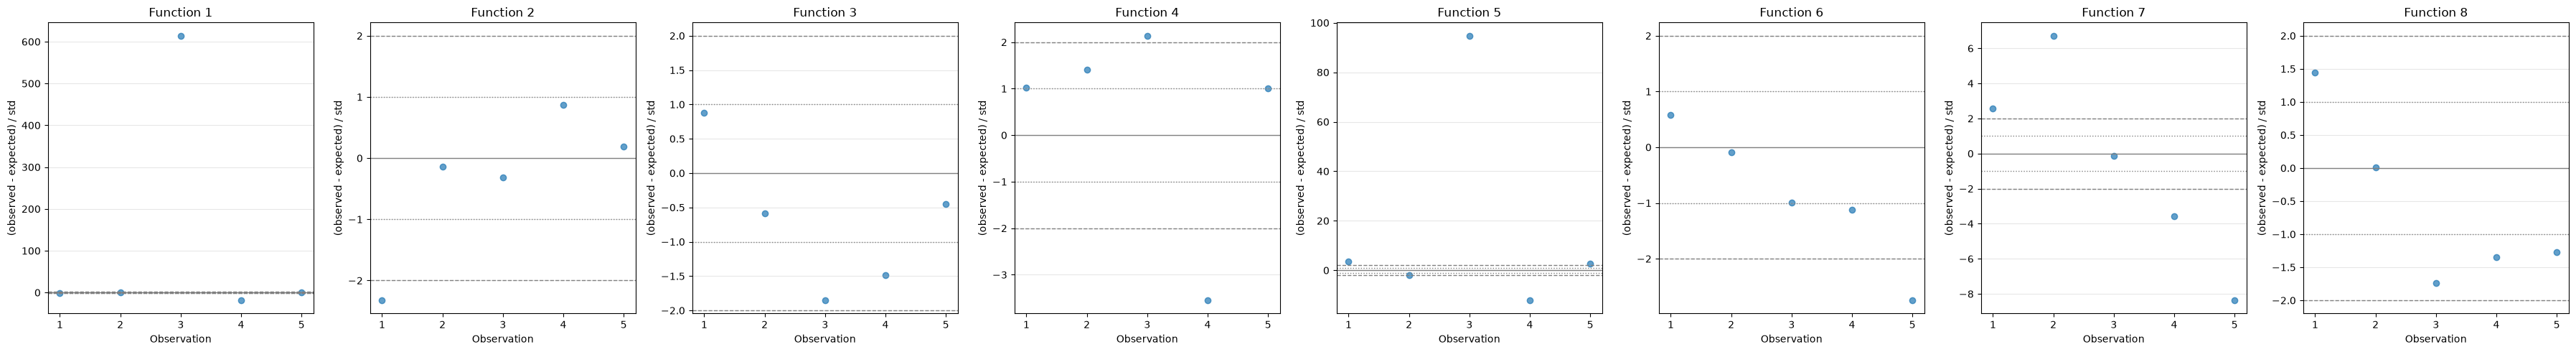

In [4]:
calibration_figure, calibration_ax = plot_calibration(residuals)
display(calibration_figure)
plt.close(progress_figure)
plt.close(calibration_figure)